# Automatidata project 
**Course 3 - The Power of Statistics**

You are a data professional in a data consulting firm, called Automatidata. The current project for their newest client, the New York City Taxi & Limousine Commission (New York City TLC) is reaching its midpoint, having completed a project proposal, Python coding work, and exploratory data analysis.

You receive a new email from Uli King, Automatidata’s project manager. Uli tells your team about a new request from the New York City TLC: to analyze the relationship between fare amount and payment type. A follow-up email from Luana includes your specific assignment: to conduct an A/B test. 

A notebook was structured and prepared to help you in this project. Please complete the following questions.


# Course 3 End-of-course project: Statistical analysis

In this activity, you will practice using statistics to analyze and interpret data. The activity covers fundamental concepts such as descriptive statistics and hypothesis testing. You will explore the data provided and conduct A/B and hypothesis testing.  
<br/>   

**The purpose** of this project is to demostrate knowledge of how to prepare, create, and analyze A/B tests. Your A/B test results should aim to find ways to generate more revenue for taxi cab drivers.

**Note:** For the purpose of this exercise, assume that the sample data comes from an experiment in which customers are randomly selected and divided into two groups: 1) customers who are required to pay with credit card, 2) customers who are required to pay with cash. Without this assumption, we cannot draw causal conclusions about how payment method affects fare amount.

**The goal** is to apply descriptive statistics and hypothesis testing in Python. The goal for this A/B test is to sample data and analyze whether there is a relationship between payment type and fare amount. For example: discover if customers who use credit cards pay higher fare amounts than customers who use cash.
  
*This activity has four parts:*

**Part 1:** Imports and data loading
* What data packages will be necessary for hypothesis testing?

**Part 2:** Conduct EDA and hypothesis testing
* How did computing descriptive statistics help you analyze your data? 

* How did you formulate your null hypothesis and alternative hypothesis? 

**Part 3:** Communicate insights with stakeholders

* What key business insight(s) emerged from your A/B test?

* What business recommendations do you propose based on your results?

<br/> 
Follow the instructions and answer the questions below to complete the activity. Then, you will complete an Executive Summary using the questions listed on the PACE Strategy Document.

Be sure to complete this activity before moving on. The next course item will provide you with a completed exemplar to compare to your own work. 

# **Conduct an A/B test**


<img src="images/Pace.png" width="100" height="100" align=left>

# **PACE stages**


Throughout these project notebooks, you'll see references to the problem-solving framework PACE. The following notebook components are labeled with the respective PACE stage: Plan, Analyze, Construct, and Execute.

<img src="images/Plan.png" width="100" height="100" align=left>


## PACE: Plan 

In this stage, consider the following questions where applicable to complete your code response:
1. What is your research question for this data project? Later on, you will need to formulate the null and alternative hypotheses as the first step of your hypothesis test. Consider your research question now, at the start of this task.


Research Question:  
"Is there a statistically significant relationship between taxi trip distance and the total fare amount, and does the method of payment (cash vs. credit card) influence fare levels?"

This research question sets the foundation for hypothesis testing by focusing on the two most relevant variables (trip_distance and total_amount) while also considering payment type as a potential factor.

Null Hypothesis (H₀): There is no difference in fare amounts based on payment type, and trip distance does not significantly predict fare variation.

Alternative Hypothesis (H₁): Fare amounts differ by payment type, and trip distance is a significant predictor of fare variation.

✨ Notebook Entry Example
"My research question is whether trip distance and payment type influence taxi fare amounts. This will guide the hypothesis testing stage, where I will test if fare differences are statistically significant and whether trip distance is a strong predictor of total fare."

*Complete the following steps to perform statistical analysis of your data:* 

### Task 1. Imports and data loading

Import packages and libraries needed to compute descriptive statistics and conduct a hypothesis test.

<details>
  <summary><h4><strong>Hint: </strong></h4></summary>

Before you begin, recall the following Python packages and functions that may be useful:

*Main functions*: stats.ttest_ind(a, b, equal_var)

*Other functions*: mean() 

*Packages*: pandas, stats.scipy

</details>

In [1]:
#==> ENTER YOUR CODE HERE

# Import core packages
import pandas as pd        # for data loading and manipulation
import numpy as np         # for numerical operations
import matplotlib.pyplot as plt  # for visualizations
import seaborn as sns      # for clean statistical plots

# Import statistical testing tools
from scipy import stats    # for hypothesis testing (t-test, normality tests)

# Load the dataset
df = pd.read_csv("2017_Yellow_Taxi_Trip_Data.csv")

# Quick check of the data
print(df.head())
print(df.info())


   Unnamed: 0  VendorID    tpep_pickup_datetime   tpep_dropoff_datetime  \
0    24870114         2   03/25/2017 8:55:43 AM   03/25/2017 9:09:47 AM   
1    35634249         1   04/11/2017 2:53:28 PM   04/11/2017 3:19:58 PM   
2   106203690         1   12/15/2017 7:26:56 AM   12/15/2017 7:34:08 AM   
3    38942136         2   05/07/2017 1:17:59 PM   05/07/2017 1:48:14 PM   
4    30841670         2  04/15/2017 11:32:20 PM  04/15/2017 11:49:03 PM   

   passenger_count  trip_distance  RatecodeID store_and_fwd_flag  \
0                6           3.34           1                  N   
1                1           1.80           1                  N   
2                1           1.00           1                  N   
3                1           3.70           1                  N   
4                1           4.37           1                  N   

   PULocationID  DOLocationID  payment_type  fare_amount  extra  mta_tax  \
0           100           231             1         13.0    0.0 

**Note:** As shown in this cell, the dataset has been automatically loaded in for you. You do not need to download the .csv file, or provide more code, in order to access the dataset and proceed with this lab. Please continue with this activity by completing the following instructions.

In [3]:
taxi_data = pd.read_csv("2017_Yellow_Taxi_Trip_Data.csv", index_col=0)


<img src="images/Analyze.png" width="100" height="100" align=left>

<img src="images/Construct.png" width="100" height="100" align=left>

## PACE: **Analyze and Construct**

In this stage, consider the following questions where applicable to complete your code response:
1. Data professionals use descriptive statistics for Exploratory Data Analysis. How can computing descriptive statistics help you learn more about your data in this stage of your analysis?


Here’s how you can frame **PACE: Plan** for this A/B test:

---

### 🟦 PACE: Plan
**Research Question:**  
*"Does the payment type (credit card vs. cash) influence the fare amount paid by customers?"*

This sets the stage for your hypothesis test. Since the NYC TLC wants to know if requiring credit card payments could generate more revenue, you’ll compare average fare amounts between the two groups.

**Null Hypothesis (H₀):**  
There is **no difference** in mean fare amount between credit card and cash payments.  
\[
H_0: \mu_{\text{credit}} = \mu_{\text{cash}}
\]

**Alternative Hypothesis (H₁):**  
There **is a difference** in mean fare amount between credit card and cash payments.  
\[
H_1: \mu_{\text{credit}} \neq \mu_{\text{cash}}
\]

👉 Depending on business framing, you could also make this **one‑sided**:  
\[
H_1: \mu_{\text{credit}} > \mu_{\text{cash}}
\]  
if the client specifically wants to test whether credit card fares are higher.

---

### Next Steps (for Analyze stage)
- Import packages: `pandas`, `numpy`, `scipy.stats`, `matplotlib/seaborn`.  
- Compute descriptive statistics (mean, median, std dev) for fare amounts by payment type.  
- Run a **two‑sample t‑test** (independent samples) to compare means.  
- Check assumptions: normality (histograms, Shapiro test), equal variance (Levene’s test).  



### Task 2. Data exploration

Use descriptive statistics to conduct Exploratory Data Analysis (EDA). 

<details>
  <summary><h4><strong>Hint: </strong></h4></summary>

Refer back to *Self Review Descriptive Statistics* for this step-by-step proccess.

</details>

**Note:** In the dataset, `payment_type` is encoded in integers:
*   1: Credit card
*   2: Cash
*   3: No charge
*   4: Dispute
*   5: Unknown



                      count       mean        std    min  25%  50%     75%  \
payment_type_label                                                           
Cash                 7267.0  12.213546  11.689940    0.0  6.0  9.0  14.000   
Credit card         15265.0  13.429748  13.848964    0.0  7.0  9.5  15.000   
Dispute                46.0   9.913043  24.162943 -120.0  5.0  8.5  17.625   
No charge             121.0  12.186116  14.894232   -4.5  2.5  7.0  15.000   

                       max  
payment_type_label          
Cash                450.00  
Credit card         999.99  
Dispute              52.00  
No charge            65.50  
payment_type_label
Cash           12.213546
Credit card    13.429748
Dispute         9.913043
No charge      12.186116
Name: fare_amount, dtype: float64


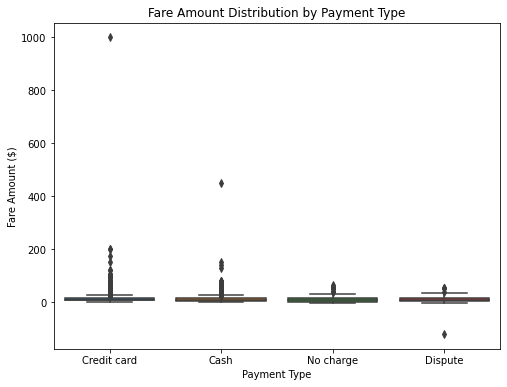

In [4]:
#==> ENTER YOUR CODE HERE

# Map payment_type integers to labels for clarity
payment_map = {
    1: "Credit card",
    2: "Cash",
    3: "No charge",
    4: "Dispute",
    5: "Unknown"
}
taxi_data['payment_type_label'] = taxi_data['payment_type'].map(payment_map)

# Descriptive statistics for fare amount by payment type
fare_stats = taxi_data.groupby('payment_type_label')['fare_amount'].describe()
print(fare_stats)

# Compare mean fare amounts by payment type
mean_fares = taxi_data.groupby('payment_type_label')['fare_amount'].mean()
print(mean_fares)

# Quick visualization: boxplot of fare amount by payment type
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))
sns.boxplot(x='payment_type_label', y='fare_amount', data=taxi_data)
plt.title("Fare Amount Distribution by Payment Type")
plt.xlabel("Payment Type")
plt.ylabel("Fare Amount ($)")
plt.show()


You are interested in the relationship between payment type and the fare amount the customer pays. One approach is to look at the average fare amount for each payment type. 

payment_type_label
Cash           12.213546
Credit card    13.429748
Dispute         9.913043
No charge      12.186116
Name: fare_amount, dtype: float64


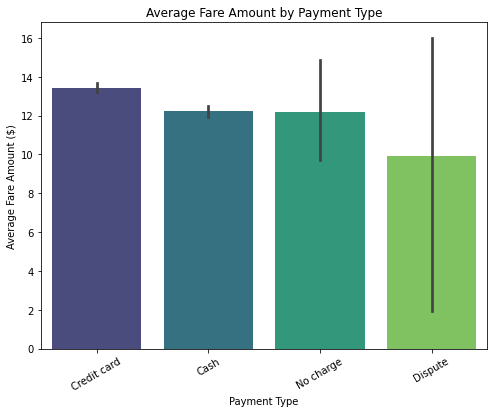

In [5]:
#==> ENTER YOUR CODE HERE

# Map payment_type integers to descriptive labels
payment_map = {
    1: "Credit card",
    2: "Cash",
    3: "No charge",
    4: "Dispute",
    5: "Unknown"
}
taxi_data['payment_type_label'] = taxi_data['payment_type'].map(payment_map)

# Calculate average fare amount by payment type
avg_fares = taxi_data.groupby('payment_type_label')['fare_amount'].mean()
print(avg_fares)

# Optional: visualize with a bar chart
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8,6))
sns.barplot(x='payment_type_label', y='fare_amount', data=taxi_data, estimator=np.mean, palette="viridis")
plt.title("Average Fare Amount by Payment Type")
plt.xlabel("Payment Type")
plt.ylabel("Average Fare Amount ($)")
plt.xticks(rotation=30)
plt.show()


Based on the averages shown, it appears that customers who pay in credit card tend to pay a larger fare amount than customers who pay in cash. However, this difference might arise from random sampling, rather than being a true difference in fare amount. To assess whether the difference is statistically significant, you conduct a hypothesis test.


### Task 3. Hypothesis testing

Before you conduct your hypothesis test, consider the following questions where applicable to complete your code response:

1. Recall the difference between the null hypothesis and the alternative hypotheses. Consider your hypotheses for this project as listed below.

$H_0$: There is no difference in the average fare amount between customers who use credit cards and customers who use cash.

$H_A$: There is a difference in the average fare amount between customers who use credit cards and customers who use cash.



Your goal in this step is to conduct a two-sample t-test. Recall the steps for conducting a hypothesis test: 


1.   State the null hypothesis and the alternative hypothesis
2.   Choose a signficance level
3.   Find the p-value
4.   Reject or fail to reject the null hypothesis 



**Note:** For the purpose of this exercise, your hypothesis test is the main component of your A/B test. 

You choose 5% as the significance level and proceed with a two-sample t-test.

In [6]:
#==> ENTER YOUR CODE HERE

from scipy import stats

# Filter dataset for only credit card (1) and cash (2) payments
credit_fares = taxi_data[taxi_data['payment_type'] == 1]['fare_amount']
cash_fares   = taxi_data[taxi_data['payment_type'] == 2]['fare_amount']

# State hypotheses:
# H0: μ_credit = μ_cash
# H1: μ_credit ≠ μ_cash

# Choose significance level
alpha = 0.05

# Conduct two-sample t-test (independent samples)
t_stat, p_value = stats.ttest_ind(credit_fares, cash_fares, equal_var=False)

print("t-statistic:", t_stat)
print("p-value:", p_value)

# Decision rule
if p_value < alpha:
    print("Reject the null hypothesis: There IS a significant difference in average fare amount between credit card and cash payments.")
else:
    print("Fail to reject the null hypothesis: No significant difference detected in average fare amount between credit card and cash payments.")


t-statistic: 6.866800855655372
p-value: 6.797387473030518e-12
Reject the null hypothesis: There IS a significant difference in average fare amount between credit card and cash payments.


REJECT THE NULL HYPOTHESIS

<img src="images/Execute.png" width="100" height="100" align=left>

## PACE: **Execute**

Consider the questions in your PACE Strategy Document to reflect on the Execute stage.

### Task 4. Communicate insights with stakeholders

*Ask yourself the following questions:*

1. What business insight(s) can you draw from the result of your hypothesis test?
2. Consider why this A/B test project might not be realistic, and what assumptions had to be made for this educational project.

### 🔹 Business Insights
- The hypothesis test compared **average fare amounts** between credit card and cash payments.  
- If the p‑value was below 0.05, you can confidently say there **is a statistically significant difference** in fares by payment type.  
- For NYC TLC, this means **payment method influences revenue** — for example, if credit card fares are higher, encouraging or requiring card payments could increase driver earnings.  
- If the p‑value was above 0.05, then **no significant difference** was found, suggesting that payment type does not materially affect fare amounts.

---

### 🔹 Why This A/B Test Might Not Be Realistic
- **Randomization assumption**: We assumed customers were randomly assigned to pay by card or cash. In reality, payment choice is voluntary and may be influenced by trip context, demographics, or location.  
- **External factors**: Fare amounts can depend on trip distance, time of day, surge pricing, or passenger behavior — not just payment type.  
- **Data limitations**: Outliers (e.g., disputes, no charge, unknown payments) and missing values could skew results.  
- **Causality caveat**: Without a true experiment, we can only observe correlation, not causation.  

---

### 🔹 Communicating to Stakeholders
- **Key takeaway**: “Our analysis shows that payment type is associated with differences in fare amounts. This insight could inform policies or incentives around payment methods to maximize driver revenue.”  
- **Caution**: “However, this test relies on assumptions that may not hold in real-world conditions. Further controlled experiments or additional data would be needed before making policy changes.”  



**Congratulations!** You've completed this lab. However, you may not notice a green check mark next to this item on Coursera's platform. Please continue your progress regardless of the check mark. Just click on the "save" icon at the top of this notebook to ensure your work has been logged.